# Intelligent Customer Support Router

A multi-task classifier that reads a customer message and decides who should handle it.

**Pipeline**
1. Label the Bitext customer-support dataset with a zero-shot model (frustration and urgency signals).
2. Add synthetic classes the dataset lacks: greetings, off-topic text, gibberish, genuinely critical and angry messages.
3. Fine-tune one DistilBERT encoder with three heads: department, sentiment, urgency.
4. Route each message into one of four tiers, using sentence-embedding retrieval to answer routine questions.
5. Evaluate on a validation split and on a hand-written gold set.

| Tier | Meaning | Action |
|---|---|---|
| 1 | Critical (fraud, repeated charges, request for a human) | Escalate to a human |
| 2 | Routine request, frustrated customer | Priority ticket for a human |
| 3 | Calm, in-domain question | Bot answers from retrieved reply |
| 4 | Greeting, off-topic, gibberish | Canned reply |

## 1. Setup

In [ ]:
import os, re, json, random, string, shutil, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 2. Data

In [ ]:
from datasets import load_dataset

SAMPLE_N = None
raw = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset")["train"].to_pandas()
df = raw[["instruction", "category", "intent", "response"]].copy()
if SAMPLE_N:
    df = df.sample(SAMPLE_N, random_state=SEED)
df = df.reset_index(drop=True)
df["instruction"] = df["instruction"].astype(str)

print(df.shape)
print("categories:", sorted(df["category"].unique()))
print("intents   :", sorted(df["intent"].unique()))

(26872, 4)
categories: ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']
intents   : ['cancel_order', 'change_order', 'change_shipping_address', 'check_cancellation_fee', 'check_invoice', 'check_payment_methods', 'check_refund_policy', 'complaint', 'contact_customer_service', 'contact_human_agent', 'create_account', 'delete_account', 'delivery_options', 'delivery_period', 'edit_account', 'get_invoice', 'get_refund', 'newsletter_subscription', 'payment_issue', 'place_order', 'recover_password', 'registration_problems', 'review', 'set_up_shipping_address', 'switch_account', 'track_order', 'track_refund']


## 3. Zero-shot signals

Two zero-shot questions are asked with a DeBERTa NLI model, and the raw entailment probability is kept rather than a hard label:

* *"The customer is angry or frustrated."* — asked for every row.
* *"This customer message describes an urgent emergency."* — asked only for rows containing a severe cue (fraud, unauthorised charge, legal threat, and similar).

Mild words such as "urgent" or "asap" are deliberately not severe cues: urgency of tone is not severity of the issue. Scores are cached to disk.

In [ ]:
from transformers import pipeline

ZS_MODEL = "MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli"
BATCH, CHUNK = 32, 1000
CACHE = f"bitext_zs_{SAMPLE_N or 'full'}.csv"


SEVERE_CUE = re.compile(
    r"unauthori[sz]ed|fraud|stolen|hack(?:ed|er)?|scam|identity theft|emergency|lawyer|legal action|"
    r"dispute (?:the|this) charge|double[- ]charged|billed (?:twice|again)|"
    r"charged (?:me )?(?:twice|two times|three times|multiple times|again)|"
    r"(?:charge|payment|transaction) (?:i|that i) (?:did not|didn't|never) (?:make|authori[sz]e|place)",
    re.I,
)
df["has_severe_cue"] = df["instruction"].str.contains(SEVERE_CUE)
print("rows with a severe cue:", int(df["has_severe_cue"].sum()))


def zs_scores(clf, texts, label, template):
    """Score ONE hypothesis per text (entailment vs contradiction) and return the raw probability."""
    out = clf(texts, candidate_labels=[label], hypothesis_template=template, multi_label=True, batch_size=BATCH)
    if isinstance(out, dict):
        out = [out]
    return [float(o["scores"][0]) for o in out]


cache_ok = False
if os.path.exists(CACHE):
    zs = pd.read_csv(CACHE)
    cache_ok = len(zs) == len(df) and (zs["instruction"].astype(str).values == df["instruction"].values).all()
    print("Loaded cached zero-shot scores" if cache_ok else "Cache does not match the data - recomputing")

if not cache_ok:
    use_gpu = torch.cuda.is_available()
    clf = pipeline("zero-shot-classification", model=ZS_MODEL, device=0 if use_gpu else -1,
                   dtype=torch.float16 if use_gpu else torch.float32)
    texts = df["instruction"].tolist()

    frus = []
    for s in tqdm(range(0, len(texts), CHUNK), desc="frustration score"):
        frus += zs_scores(clf, texts[s:s + CHUNK], "angry or frustrated", "The customer is {}.")

    crit = np.full(len(df), np.nan)
    cue_idx = np.where(df["has_severe_cue"].values)[0]
    if len(cue_idx):
        vals = zs_scores(clf, [texts[i] for i in cue_idx], "an urgent emergency", "This customer message describes {}.")
        crit[cue_idx] = vals

    zs = pd.DataFrame({"instruction": texts, "frus_score": np.round(frus, 4), "crit_score": np.round(crit, 4)})
    zs.to_csv(CACHE, index=False)
    del clf
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

df["frus_score"] = zs["frus_score"].values
df["crit_score"] = zs["crit_score"].values
print(df[["instruction", "intent", "frus_score", "crit_score"]].head())

rows with a severe cue: 4


                                         instruction        intent  \
0   question about cancelling order {{Order Number}}  cancel_order   
1  i have a question about cancelling oorder {{Or...  cancel_order   
2    i need help cancelling puchase {{Order Number}}  cancel_order   
3         I need to cancel purchase {{Order Number}}  cancel_order   
4  I cannot afford this order, cancel purchase {{...  cancel_order   

   frus_score  crit_score  
0      0.8047         NaN  
1      0.7458         NaN  
2      0.9547         NaN  
3      0.8776         NaN  
4      0.8626         NaN  


## 4. Turning scores into labels

**Sentiment.** Bitext consists mostly of calm questions, so the default is `neutral`. A row becomes `frustrated` if
* its score exceeds an adaptive threshold, `max(0.70, 92nd percentile of scores)`, which caps the frustrated share at about 8 %, or
* its score is at least 0.50 and the text has lexical evidence of anger (all caps, `!!`, `?!`, anger words).

**Urgency.** `routine` by default. A row is `critical` if its intent is `contact_human_agent` (a business rule), or if it has a severe cue and the zero-shot model confirms it.

In [ ]:
FRUS_FLOOR, MAX_FRUS_SHARE = 0.70, 0.08
CRIT_THR = 0.70
ALWAYS_ESCALATE = {"contact_human_agent"}

missing = ALWAYS_ESCALATE - set(df["intent"].unique())
if missing:
    warnings.warn(f"Intent(s) {missing} not found in this dataset version - check ALWAYS_ESCALATE")

ANGER_WORDS = re.compile(
    r"ridiculous|unacceptable|furious|angry|terrible|awful|worst|useless|sick of|fed up|annoy|frustrat|disgust|outrag|"
    r"pathetic|incompetent|stupid|idiot|damn|rubbish|garbage|disappointed|nobody (?:ever )?(?:answers|helps)", re.I)


def has_anger_cue(t: str) -> bool:
    letters = [c for c in t if c.isalpha()]
    shouting = len(letters) >= 8 and sum(c.isupper() for c in letters) / len(letters) > 0.6
    return bool(shouting or re.search(r"!{2,}|\?!|!\?|\?{2,}", t) or ANGER_WORDS.search(t))


df["anger_cue"] = df["instruction"].map(has_anger_cue)

FRUS_THR = max(FRUS_FLOOR, float(df["frus_score"].quantile(1 - MAX_FRUS_SHARE)))
is_frus = (df["frus_score"] >= FRUS_THR) | ((df["frus_score"] >= 0.50) & df["anger_cue"])
is_crit = df["intent"].isin(ALWAYS_ESCALATE) | (df["has_severe_cue"] & (df["crit_score"] >= CRIT_THR))

df["sentiment_label"] = np.where(is_frus, "frustrated", "neutral")
df["urgency_label"] = np.where(is_crit, "critical", "routine")
print(f"adaptive frustration threshold = {FRUS_THR:.3f}")

adaptive frustration threshold = 0.966


In [ ]:
print(df["urgency_label"].value_counts(normalize=True).round(3), "\n")
print(df["sentiment_label"].value_counts(normalize=True).round(3), "\n")
print(pd.crosstab(df["urgency_label"], df["sentiment_label"]), "\n")

crit_share = (df["urgency_label"] == "critical").mean()
frus_share = (df["sentiment_label"] == "frustrated").mean()
if crit_share > 0.10:
    warnings.warn(f"{crit_share:.1%} of Bitext is critical - expected a small minority. Check SEVERE_CUE / CRIT_THR.")
if frus_share > 0.12:
    warnings.warn(f"{frus_share:.1%} of Bitext is frustrated - expected a small minority. Lower MAX_FRUS_SHARE.")

print("--- sample 'critical' rows ---")
print(df[df["urgency_label"] == "critical"]["instruction"].sample(min(8, int(is_crit.sum())), random_state=1).to_string(index=False))
print("--- sample 'frustrated' rows ---")
print(df[df["sentiment_label"] == "frustrated"]["instruction"].sample(min(8, int(is_frus.sum())), random_state=1).to_string(index=False))
print("--- borderline (score 0.5 - threshold, no anger cue): these are now NEUTRAL ---")
border = df[(df["frus_score"] >= 0.5) & (df["frus_score"] < FRUS_THR) & ~df["anger_cue"]]
print(border["instruction"].head(8).to_string(index=False))

urgency_label
routine     0.963
critical    0.037
Name: proportion, dtype: float64 

sentiment_label
neutral       0.918
frustrated    0.082
Name: proportion, dtype: float64 

sentiment_label  frustrated  neutral
urgency_label                       
critical                 74      929
routine                2122    23747 

--- sample 'critical' rows ---
       what do I need to do to chat with somebody?
                      how to contact an assistant?
                   help chatting with an assistant
                     I want to contact an operator
                              contact a live agent
i do not kniw what i need to do to speak with a...
                         Ineed to contact an agent
             I want help speaking with an operator
--- sample 'frustrated' rows ---
i expect a restitution of {{Refund Amount}} dol...
            help me seeing your damn refund policy
i dont know what i have to do to remove my {{Ac...
   what fucking hours can I call customer support

## 5. Synthetic training data

Bitext has almost no greetings, gibberish, off-topic text or genuinely critical messages. These are generated so the model sees every class:

* greetings and small talk, and greeting followed by a real request
* gibberish and polite off-topic requests
* critical issues phrased both politely and angrily, so urgency is independent of tone
* frustrated-but-routine and urgent-sounding-but-routine requests built on real Bitext questions

In [ ]:
rng = random.Random(SEED)
GENERAL = "GENERAL"


def _case(s):
    r = rng.random()
    return s.upper() if r < 0.10 else (s.capitalize() if r < 0.60 else s)


def _punct(s):
    return s + rng.choice(["", "", ".", "!", "!!"])


def _make_df(rows, urgency, sentiment, source):
    return pd.DataFrame([{"instruction": t, "category": d, "urgency_label": urgency,
                          "sentiment_label": sentiment, "source": source} for t, d in rows])


NAMES = ["x", "john", "priya", "sam", "alex", "maria", "ahmed", "lee", "sara", "david"]
OPENERS = ["hello", "hi", "hey", "hey there", "hi there", "hello there", "good morning", "good afternoon", "good evening",
           "greetings", "howdy", "yo", "hola", "namaste", "hii", "helloo"]
BODIES = ["", "", "", "my name is {name}", "i am {name}", "this is {name}", "how are you", "how are you doing", "how's it going",
          "what's up", "is anyone there", "can you hear me", "are you a bot", "who are you", "what can you do", "nice to meet you",
          "hope you are doing well", "just saying hi", "testing"]
SMALLTALK = ["thanks", "thank you", "thank you so much", "thanks a lot", "ok thanks", "great, thanks", "that's all", "bye", "goodbye",
             "see you", "have a nice day", "cool", "okay", "nice", "awesome", "lol", "haha", "good job", "you're helpful", "thanks, bye"]
greet = set()
for _ in range(6000):
    if rng.random() < 0.8:
        body = rng.choice(BODIES).format(name=rng.choice(NAMES))
        t = f"{rng.choice(OPENERS)}, {body}" if body else rng.choice(OPENERS)
    else:
        t = rng.choice(SMALLTALK)
    greet.add(_punct(_case(t)))
greet = rng.sample(sorted(greet), min(1500, len(greet)))


GIBBERISH = ["asdfgh", "qwerty", "zxcvbnm", "asdf jkl", "hjkl", "lorem ipsum dolor sit amet", "blah blah blah", "???", "...", "12345",
             "aaaaaa", "test test", "xyz", "hmm", "uhhh", "lalala", "abc", "random text here", "banana", "purple monkey dishwasher"]
OFFTOPIC = ["what is the capital of france", "tell me a joke", "who won the world cup", "what's the weather like today",
            "write a poem about the ocean", "how do i cook pasta", "what is 25 times 4", "who is the president", "recommend a good movie",
            "what is the meaning of life", "how tall is mount everest", "sing me a song", "what is your favorite color",
            "translate good morning to french", "how do i learn python", "which football team is the best", "do aliens exist",
            "what is the speed of light", "give me a recipe for pizza", "how many days are in a year"]
OFFTOPIC_ASKS = ["tell me a joke", "give me a recipe for lasagna", "write a poem about autumn", "recommend a good book",
                 "tell me who won the football match", "tell me the weather forecast", "explain quantum physics", "sing me a song",
                 "help me with my maths homework", "translate thank you into spanish", "tell me about the history of rome",
                 "suggest a name for my dog", "tell me a fun fact about space", "write python code to sort a list",
                 "give me some workout tips", "tell me a bedtime story", "tell me the latest news", "what is the best phone to buy"]
ASK_WRAP = ["can you {x}", "could you {x}", "please {x}", "hi, can you {x}", "i was wondering if you could {x}", "would you {x}", "hey, {x}"]


def _gib():
    return "".join(rng.choice(string.ascii_lowercase) for _ in range(rng.randint(3, 14)))


nonsense = set(GIBBERISH) | set(OFFTOPIC)
for _ in range(700): nonsense.add(_gib())
for _ in range(300): nonsense.add(" ".join(_gib() for _ in range(rng.randint(2, 4))))
for _ in range(400): nonsense.add(_punct(_case(rng.choice(OFFTOPIC))))
for _ in range(900):
    asks = rng.sample(OFFTOPIC_ASKS, rng.choice([1, 1, 2]))
    nonsense.add(_punct(_case(rng.choice(ASK_WRAP).format(x=" or ".join(asks)))))
nonsense = sorted(nonsense)


CRITICAL_CORES = [
    ("my account has been hacked", "ACCOUNT"),
    ("someone logged into my account and changed my password", "ACCOUNT"),
    ("i think my identity was stolen and used on your site", "ACCOUNT"),
    ("i am locked out of my account and someone else is using it", "ACCOUNT"),
    ("somebody is using my account to place orders", "ACCOUNT"),
    ("i got an email saying my password changed but it was not me", "ACCOUNT"),
    ("there is an unauthorized transaction on my card", "PAYMENT"),
    ("i was charged for an order i never placed", "PAYMENT"),
    ("my card was charged multiple times for the same order", "PAYMENT"),
    ("i was charged twice and the money is gone from my account", "PAYMENT"),
    ("my payment went through but i keep getting billed again", "PAYMENT"),
    ("i am going to dispute the charge with my bank and call my lawyer", "PAYMENT"),
    ("someone used my card details to buy things from your store", "PAYMENT"),
    ("you took the money from my account three times", "PAYMENT"),
    ("the payment was taken but the amount is wrong and my account is overdrawn", "PAYMENT"),
    ("a large refund is missing and i cannot pay my rent", "REFUND"),
    ("you promised a refund weeks ago and i still have nothing and need the money now", "REFUND"),
    ("the product i received is dangerous and could hurt someone", "ORDER"),
    ("the item i got is leaking and could start a fire", "ORDER"),
    ("my order with medication i need today was delivered to a stranger", "DELIVERY"),
    ("my package with important documents was delivered to the wrong person", "DELIVERY"),
    ("i need to speak to a human agent", "CONTACT"),
    ("connect me to a live agent", "CONTACT"),
    ("i want to talk to a real person", "CONTACT"),
    ("transfer me to a human representative", "CONTACT"),
    ("i need a manager to help me with a serious problem", "CONTACT"),
    ("this is an emergency", "CONTACT"),
    ("i want to report fraud on my account", "ACCOUNT"),
    ("i am being scammed by someone using your company name", "CONTACT"),
    ("i will take legal action if this is not fixed", "CONTACT"),
]
POLITE_PRE = ["", "hello, ", "hi, ", "good morning, ", "excuse me, ", "hello, i hope you can help. ", "please help, "]
URGENT_MARKS = ["", "this is urgent. ", "urgent: ", "it is critical. ", "i need help right now. ", "please help me immediately. ", "this is an emergency. "]
POLITE_POST = ["", " please escalate this.", " please connect me to an agent.", " thank you.", " kindly help asap.", " i need a human to look at this now."]
ANGRY_POST = [" this is unacceptable!", " i am furious!!", " fix this NOW!", " worst service ever.", " i am sick of waiting!", " are you kidding me?!"]


def _critical(angry):
    core, dept = rng.choice(CRITICAL_CORES)
    if angry:
        t = rng.choice(URGENT_MARKS) + core + "!" + rng.choice(ANGRY_POST)
        t = t.upper() if rng.random() < 0.5 else t
    else:
        t = rng.choice(POLITE_PRE) + rng.choice(URGENT_MARKS) + core + "." + rng.choice(POLITE_POST)
    return t.strip(), dept


def _unique_critical(angry, n):
    out = {}
    for _ in range(n * 20):
        t, d = _critical(angry)
        out[t] = d
        if len(out) >= n:
            break
    return list(out.items())


crit_polite = _unique_critical(angry=False, n=900)
crit_angry = _unique_critical(angry=True, n=900)


base = df[["instruction", "category", "urgency_label", "sentiment_label"]].copy()
base["source"] = "bitext"

FRUS_PRE = ["ugh,", "this is so annoying,", "i'm really fed up.", "seriously?", "come on,", "this is ridiculous,",
            "i can't believe i have to ask again,", "for the third time,", "are you kidding me?", "i'm losing my patience,",
            "this is getting old,", "why is nobody helping?", "i'm so tired of this,", "unbelievable."]
FRUS_POST = ["this is so frustrating!", "i'm sick of this.", "why is this so hard??", "terrible service.", "i'm very disappointed.",
             "this is unacceptable.", "i've had enough.", "worst experience ever!", "i'm really upset about this.", "you people are useless.",
             "this is a joke.", "nobody ever answers me."]
URGENT_ROUTINE_PRE = ["this is urgent. ", "urgent: ", "i need help asap. ", "quick question: ", "please help me quickly. "]

calm_pool = base[(base["urgency_label"] == "routine") & (base["sentiment_label"] == "neutral")]


def _annoy(t):
    t = f"{rng.choice(FRUS_PRE)} {t}" if rng.random() < 0.5 else f"{t} {rng.choice(FRUS_POST)}"
    return t.upper() if rng.random() < 0.3 else t


frus = calm_pool.sample(min(1500, len(calm_pool)), random_state=SEED).copy()
frus["instruction"] = frus["instruction"].map(_annoy)
frus["sentiment_label"] = "frustrated"
frus["source"] = "synthetic_frustrated_routine"

urgent_routine = calm_pool.sample(min(600, len(calm_pool)), random_state=SEED + 1).copy()
urgent_routine["instruction"] = [rng.choice(URGENT_ROUTINE_PRE) + t for t in urgent_routine["instruction"]]
urgent_routine["source"] = "synthetic_urgent_but_routine"

mixed = calm_pool.sample(min(1500, len(calm_pool)), random_state=SEED + 2).copy()
mixed["instruction"] = [f"{rng.choice(OPENERS)}{rng.choice([',', '!', ''])} {t}" for t in mixed["instruction"]]
mixed["source"] = "synthetic_greeting_plus_request"

print({"greet": len(greet), "nonsense": len(nonsense), "crit_polite": len(crit_polite), "crit_angry": len(crit_angry),
       "frus": len(frus), "urgent_routine": len(urgent_routine), "mixed": len(mixed)})

{'greet': 1500, 'nonsense': 1943, 'crit_polite': 900, 'crit_angry': 900, 'frus': 1500, 'urgent_routine': 600, 'mixed': 1500}


## 6. Gold test set

Hand-written messages with the expected tier, phrased differently from the templates above. Any gold message that also appears in the training data is removed from training.
Each entry is `(text, expected_tier, kind)`.

In [ ]:
GOLD = [

    ("WHY WAS MY CARD CHARGED THREE TIMES FOR ONE ORDER?! REFUND MY MONEY RIGHT NOW!", 1, "critical"),
    ("Someone got into my account and placed orders I never made. Please help urgently.", 1, "critical"),
    ("There is a charge on my credit card from your store that I did not authorize.", 1, "critical"),
    ("I want to talk to a real person about my order, can you transfer me?", 1, "critical"),
    ("Hello, I would really appreciate it if I could speak with a human representative.", 1, "critical"),
    ("My payment was taken twice and now my bank account is overdrawn!!", 1, "critical"),
    ("I think somebody stole my login details and is buying things with my saved card.", 1, "critical"),

    ("Third time asking: how do I change my shipping address? Nobody ever answers!", 2, "frustrated"),
    ("Your website keeps crashing when I try to track my order and I am really fed up with it.", 2, "frustrated"),
    ("WHY IS IT SO HARD TO CANCEL MY NEWSLETTER SUBSCRIPTION?? I AM SICK OF THIS", 2, "frustrated"),
    ("I've been waiting ages for my invoice and nobody has bothered to reply. Pathetic service.", 2, "frustrated"),
    ("This is ridiculous, I just want to update my email address and your form is broken again.", 2, "frustrated"),

    ("What payment methods do you accept for orders?", 3, "faq"),
    ("Can you tell me how to change my shipping address?", 3, "faq"),
    ("Hello! how can i get refund", 3, "faq"),
    ("How do I recover my password?", 3, "faq"),
    ("I need to cancel my newsletter subscription.", 3, "faq"),
    ("Where can I find the invoice for my last purchase?", 3, "faq"),
    ("how long does delivery usually take", 3, "faq"),
    ("Could you help me create an account?", 3, "faq"),
    ("What is your refund policy for returned items?", 3, "faq"),
    ("I would like to track my order please", 3, "faq"),
    ("Hi, can I change the delivery address of an order I already placed?", 3, "faq"),

    ("hello", 4, "greeting"),
    ("hello my name is x", 4, "greeting"),
    ("Hey there, good evening!", 4, "greeting"),
    ("thanks, bye", 4, "greeting"),
    ("Can you tell me a joke or give me a recipe for pasta?", 4, "offtopic"),
    ("What's the weather going to be like tomorrow?", 4, "offtopic"),
    ("who won the cricket match yesterday", 4, "offtopic"),
    ("Please explain how black holes form.", 4, "offtopic"),
    ("asdfgh qwerty", 4, "gibberish"),
    ("???", 4, "gibberish"),
    ("kjhsdf lkjwe", 4, "gibberish"),
]
gold_df = pd.DataFrame(GOLD, columns=["text", "expected_tier", "kind"])
print(gold_df["expected_tier"].value_counts().sort_index().to_dict(), "| total", len(gold_df))

{1: 7, 2: 5, 3: 11, 4: 11} | total 34


In [ ]:
def norm(s: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", "", str(s).lower())).strip()


SYN = lambda rows, urg, sen, src: _make_df([(t, GENERAL) for t in rows], urg, sen, src)
full_df = pd.concat([
    base,
    frus,
    urgent_routine[["instruction", "category", "urgency_label", "sentiment_label", "source"]],
    mixed[["instruction", "category", "urgency_label", "sentiment_label", "source"]],
    SYN(greet, "greeting", "casual", "synthetic_greeting"),
    SYN(nonsense, "nonsense", "casual", "synthetic_nonsense"),
    _make_df(crit_polite, "critical", "neutral", "synthetic_critical_polite"),
    _make_df(crit_angry, "critical", "frustrated", "synthetic_critical_angry"),
], ignore_index=True)


full_df["_n"] = full_df["instruction"].map(norm)
n0 = len(full_df)
full_df = full_df.drop_duplicates("_n", keep="first")
n_dups = n0 - len(full_df)
gold_norm = set(gold_df["text"].map(norm))
leak = full_df["_n"].isin(gold_norm)
print(f"dropped {n_dups} duplicate rows and {int(leak.sum())} gold-overlapping rows from training")
full_df = full_df[~leak].drop(columns="_n").reset_index(drop=True)

print("full_df:", full_df.shape)
print(full_df.groupby("source").size(), "\n")
print(pd.crosstab(full_df["urgency_label"], full_df["sentiment_label"]))

dropped 4536 duplicate rows and 3 gold-overlapping rows from training
full_df: (31176, 5)
source
bitext                             23984
synthetic_critical_angry             745
synthetic_critical_polite            900
synthetic_frustrated_routine        1498
synthetic_greeting                   522
synthetic_greeting_plus_request     1499
synthetic_nonsense                  1428
synthetic_urgent_but_routine         600
dtype: int64 

sentiment_label  casual  frustrated  neutral
urgency_label                               
critical              0         819     1797
greeting            522           0        0
nonsense           1428           0        0
routine               0        3538    23072


In [ ]:
from sklearn.preprocessing import LabelEncoder

department_encoder, urgency_encoder, sentiment_encoder = LabelEncoder(), LabelEncoder(), LabelEncoder()
full_df["department_id"] = department_encoder.fit_transform(full_df["category"])
full_df["urgency_id"] = urgency_encoder.fit_transform(full_df["urgency_label"])
full_df["sentiment_id"] = sentiment_encoder.fit_transform(full_df["sentiment_label"])

num_departments = len(department_encoder.classes_)
num_urgencies = len(urgency_encoder.classes_)
num_sentiments = len(sentiment_encoder.classes_)
print("Departments:", list(department_encoder.classes_))
print("Urgencies  :", list(urgency_encoder.classes_))
print("Sentiments :", list(sentiment_encoder.classes_))

Departments: ['ACCOUNT', 'CANCEL', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'GENERAL', 'INVOICE', 'ORDER', 'PAYMENT', 'REFUND', 'SHIPPING', 'SUBSCRIPTION']
Urgencies  : ['critical', 'greeting', 'nonsense', 'routine']
Sentiments : ['casual', 'frustrated', 'neutral']


## 7. Train / validation split

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer

MAX_LEN, BS = 64, 32
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

strat = full_df["urgency_label"] + "|" + full_df["sentiment_label"]
try:
    train_df, val_df = train_test_split(full_df, test_size=0.2, random_state=SEED, stratify=strat)
except ValueError:
    train_df, val_df = train_test_split(full_df, test_size=0.2, random_state=SEED, stratify=full_df["urgency_label"])
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)


def make_dataset(frame):
    enc = tokenizer(frame["instruction"].astype(str).tolist(), truncation=True, padding="max_length",
                    max_length=MAX_LEN, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"],
                         torch.tensor(frame["department_id"].values.astype("int64")),
                         torch.tensor(frame["sentiment_id"].values.astype("int64")),
                         torch.tensor(frame["urgency_id"].values.astype("int64")))


train_loader = DataLoader(make_dataset(train_df), batch_size=BS, shuffle=True)
val_loader = DataLoader(make_dataset(val_df), batch_size=128, shuffle=False)
print(f"Train: {len(train_df)} | Val: {len(val_df)}")

Train: 24940 | Val: 6236


## 8. Model

One DistilBERT encoder shared by three linear heads, using the `[CLS]` representation.

In [ ]:
from transformers import DistilBertModel


class MultiTaskSupportRouter(nn.Module):
    def __init__(self, n_dept, n_urg, n_sent):
        super().__init__()
        self.distilbert = DistilBertModel.from_pretrained("distilbert-base-uncased")
        h = self.distilbert.config.hidden_size
        self.dropout = nn.Dropout(0.3)
        self.department_classifier = nn.Linear(h, n_dept)
        self.sentiment_classifier = nn.Linear(h, n_sent)
        self.urgency_classifier = nn.Linear(h, n_urg)

    def forward(self, input_ids, attention_mask):
        out = self.distilbert(input_ids=input_ids, attention_mask=attention_mask)
        pooled = self.dropout(out.last_hidden_state[:, 0, :])
        return self.department_classifier(pooled), self.sentiment_classifier(pooled), self.urgency_classifier(pooled)


model = MultiTaskSupportRouter(num_departments, num_urgencies, num_sentiments).to(device)

## 9. Training

Class-weighted cross-entropy (weights softened with a square root so rare classes such as `critical` are not drowned out), linear warm-up and decay, gradient clipping, validation after every epoch, and restoration of the best epoch.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report
from transformers import get_linear_schedule_with_warmup

EPOCHS, LR = 4, 3e-5
HEADS = ["department", "sentiment", "urgency"]
ID_COL = {"department": "department_id", "sentiment": "sentiment_id", "urgency": "urgency_id"}


def class_weights(col, n):
    w = compute_class_weight("balanced", classes=np.arange(n), y=train_df[col].values)
    return torch.tensor(np.sqrt(w), dtype=torch.float).to(device)


crit_dept = nn.CrossEntropyLoss(weight=class_weights("department_id", num_departments))
crit_sent = nn.CrossEntropyLoss(weight=class_weights("sentiment_id", num_sentiments))
crit_urg = nn.CrossEntropyLoss(weight=class_weights("urgency_id", num_urgencies))
LOSS_W = {"department": 1.0, "sentiment": 1.0, "urgency": 1.0}

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)


@torch.no_grad()
def run_eval(loader):
    model.eval()
    preds = {h: [] for h in HEADS}
    for ids, mask, *_ in loader:
        d, s, u = model(ids.to(device), mask.to(device))
        preds["department"].append(d.argmax(1).cpu()); preds["sentiment"].append(s.argmax(1).cpu()); preds["urgency"].append(u.argmax(1).cpu())
    return {h: torch.cat(v).numpy() for h, v in preds.items()}


def score(preds, frame):
    return {
        "dept_acc": float((preds["department"] == frame["department_id"].values).mean()),
        "sent_macroF1": float(f1_score(frame["sentiment_id"].values, preds["sentiment"], average="macro")),
        "urg_macroF1": float(f1_score(frame["urgency_id"].values, preds["urgency"], average="macro")),
    }


best_score, best_state = -1.0, None
for epoch in range(EPOCHS):
    model.train()
    running = 0.0
    bar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}")
    for ids, mask, y_d, y_s, y_u in bar:
        ids, mask, y_d, y_s, y_u = ids.to(device), mask.to(device), y_d.to(device), y_s.to(device), y_u.to(device)
        optimizer.zero_grad()
        ld, ls, lu = model(ids, mask)
        loss = LOSS_W["department"] * crit_dept(ld, y_d) + LOSS_W["sentiment"] * crit_sent(ls, y_s) + LOSS_W["urgency"] * crit_urg(lu, y_u)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step()
        running += loss.item()
        bar.set_postfix(loss=f"{loss.item():.4f}")
    sc = score(run_eval(val_loader), val_df)
    mean_sc = float(np.mean(list(sc.values())))
    sc_str = {k: round(v, 4) for k, v in sc.items()}
    print(f"epoch {epoch + 1}: train_loss={running / len(train_loader):.4f} | val={sc_str} | mean={mean_sc:.4f}")
    if mean_sc > best_score:
        best_score = mean_sc
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

model.load_state_dict(best_state)
model.to(device).eval()
print("restored best epoch, mean val score =", round(best_score, 4))

epoch 1: train_loss=0.8222 | val={'dept_acc': 0.9995, 'sent_macroF1': 0.974, 'urg_macroF1': 0.9966} | mean=0.9901


epoch 2: train_loss=0.0850 | val={'dept_acc': 0.9997, 'sent_macroF1': 0.9753, 'urg_macroF1': 0.9974} | mean=0.9908


epoch 3: train_loss=0.0571 | val={'dept_acc': 0.9998, 'sent_macroF1': 0.9787, 'urg_macroF1': 0.9976} | mean=0.9921


epoch 4: train_loss=0.0382 | val={'dept_acc': 0.9998, 'sent_macroF1': 0.9778, 'urg_macroF1': 0.9984} | mean=0.9920
restored best epoch, mean val score = 0.9921


## 10. Validation

Scores here should be read with two limits in mind:
* Department accuracy is near-perfect because Bitext is template-generated and near-duplicates land in both splits. It is not evidence of real-world accuracy.
* Urgency and sentiment scores measure agreement with the labelling rules in sections 3–5, not with human judgement.

The gold set in section 14 is the more meaningful check.

In [ ]:
val_preds = run_eval(val_loader)
print(score(val_preds, val_df), "\n")
print("URGENCY\n", classification_report(val_df["urgency_id"], val_preds["urgency"], target_names=urgency_encoder.classes_, digits=3))
print("SENTIMENT\n", classification_report(val_df["sentiment_id"], val_preds["sentiment"], target_names=sentiment_encoder.classes_, digits=3))


tmp = val_df.copy()
tmp["urg_ok"] = val_preds["urgency"] == tmp["urgency_id"].values
tmp["sent_ok"] = val_preds["sentiment"] == tmp["sentiment_id"].values
print(tmp.groupby("source")[["urg_ok", "sent_ok"]].mean().round(3).assign(n=tmp.groupby("source").size()))

{'dept_acc': 0.9998396407953817, 'sent_macroF1': 0.9786818204953454, 'urg_macroF1': 0.997643501430691} 

URGENCY
               precision    recall  f1-score   support

    critical      1.000     0.998     0.999       523
    greeting      0.990     1.000     0.995       104
    nonsense      0.997     0.997     0.997       286
     routine      1.000     1.000     1.000      5323

    accuracy                          1.000      6236
   macro avg      0.997     0.999     0.998      6236
weighted avg      1.000     1.000     1.000      6236

SENTIMENT
               precision    recall  f1-score   support

      casual      1.000     1.000     1.000       390
  frustrated      0.957     0.935     0.945       872
     neutral      0.989     0.993     0.991      4974

    accuracy                          0.985      6236
   macro avg      0.982     0.976     0.979      6236
weighted avg      0.985     0.985     0.985      6236

                                 urg_ok  sent_ok     n
sour

## 11. Prediction function

In [ ]:
@torch.no_grad()
def predict_support_ticket(text):
    """Returns the top label AND the full probability distribution for every head (the router needs the distributions)."""
    model.eval()
    enc = tokenizer(text, truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt").to(device)
    d, s, u = model(enc["input_ids"], enc["attention_mask"])

    def head(logits, encoder):
        p = torch.softmax(logits, dim=1)[0].cpu().numpy()
        probs = {c: round(float(x), 4) for c, x in zip(encoder.classes_, p)}
        top = max(probs, key=probs.get)
        return top, probs[top], probs

    dept, dept_conf, dept_probs = head(d, department_encoder)
    sent, sent_conf, sent_probs = head(s, sentiment_encoder)
    urg, urg_conf, urg_probs = head(u, urgency_encoder)
    return {"text": text, "department": dept, "department_confidence": dept_conf, "department_probs": dept_probs,
            "sentiment": sent, "sentiment_confidence": sent_conf, "sentiment_probs": sent_probs,
            "urgency": urg, "urgency_confidence": urg_conf, "urgency_probs": urg_probs}


for msg in ["hello", "asdfgh", "What payment methods do you accept for orders?", "Hello! how can i get refund",
            "WHY WAS MY CARD CHARGED THREE TIMES FOR ONE ORDER?! REFUND MY MONEY RIGHT NOW!"]:
    r = predict_support_ticket(msg)
    print(f"{msg!r}\n   urgency={r['urgency_probs']}\n   sentiment={r['sentiment_probs']}\n   dept={r['department']} ({r['department_confidence']})\n")

'hello'
   urgency={'critical': 0.0004, 'greeting': 0.9973, 'nonsense': 0.002, 'routine': 0.0003}
   sentiment={'casual': 0.9981, 'frustrated': 0.0001, 'neutral': 0.0018}
   dept=GENERAL (0.9955)

'asdfgh'
   urgency={'critical': 0.0001, 'greeting': 0.0003, 'nonsense': 0.9996, 'routine': 0.0}
   sentiment={'casual': 0.9998, 'frustrated': 0.0001, 'neutral': 0.0001}
   dept=GENERAL (0.9991)

'What payment methods do you accept for orders?'
   urgency={'critical': 0.0002, 'greeting': 0.0001, 'nonsense': 0.0001, 'routine': 0.9996}
   sentiment={'casual': 0.0002, 'frustrated': 0.0005, 'neutral': 0.9994}
   dept=PAYMENT (0.9989)

'Hello! how can i get refund'
   urgency={'critical': 0.0005, 'greeting': 0.0004, 'nonsense': 0.0003, 'routine': 0.9987}
   sentiment={'casual': 0.0004, 'frustrated': 0.0011, 'neutral': 0.9985}
   dept=REFUND (0.9993)

'WHY WAS MY CARD CHARGED THREE TIMES FOR ONE ORDER?! REFUND MY MONEY RIGHT NOW!'
   urgency={'critical': 0.9959, 'greeting': 0.0012, 'nonsense': 0.00

## 12. Routing policy

Routing is rule-based on top of the model's probabilities, applied in this order:

1. `P(critical) ≥ 0.50` → Tier 1, escalate to a human.
2. `0.25 ≤ P(critical) < 0.50` → Tier 2, priority ticket.
3. Urgency head predicts greeting or nonsense → Tier 4, canned reply.
4. `P(frustrated) ≥ 0.60` → Tier 2, human follow-up.
5. Otherwise retrieve the closest known question. Similarity below the calibrated threshold → Tier 4; otherwise Tier 3, answer with the retrieved reply.

In [ ]:
ROUTING_SRC = r'''
import re
import numpy as np

GENERAL = "GENERAL"

CFG = {
    "escalate_crit_prob": 0.50,
    "review_crit_prob": 0.25,
    "frustrated_prob": 0.60,
    "dept_filter_conf": 0.60,
    "retrieval_min_sim": 0.55,
}

TIER_REPLIES = {
    "escalate": "I am sorry about this. I am passing your case to a human agent right now.",
    "priority": "Thank you for reporting this. A specialist will review your case as a priority.",
    "frustrated": "I am sorry for the trouble. A human agent will follow up with you shortly.",
    "greeting": "Hello! I can help with orders, payments, refunds, shipping, invoices and your account. What do you need?",
    "off_topic": "I can only help with customer support questions. Could you tell me what you need help with?",
}


def clean_response(text):
    text = re.sub(r"\{\{\s*([^{}]*?)\s*\}\}", lambda m: f"[{m.group(1).lower()}]", str(text))
    return re.sub(r"[ \t]+", " ", text).strip()


def best_match(query_emb, pool_embs, pool_cats, dept, dept_conf, cfg):
    sims = pool_embs @ query_emb
    if dept != GENERAL and dept_conf >= cfg["dept_filter_conf"]:
        mask = pool_cats == dept
        if mask.any():
            sims = np.where(mask, sims, -1.0)
    i = int(sims.argmax())
    return i, float(sims[i])


def route_ticket(pred, retrieve_fn, create_ticket_fn=None, cfg=CFG):
    p_crit = pred["urgency_probs"]["critical"]
    p_frus = pred["sentiment_probs"]["frustrated"]
    top_urgency = max(pred["urgency_probs"], key=pred["urgency_probs"].get)

    def finish(tier, action, reason, reply, priority=None, sim=None, matched=None):
        ticket_id = None
        if priority and create_ticket_fn:
            ticket_id = create_ticket_fn(pred["text"], pred["department"], top_urgency,
                                         max(pred["sentiment_probs"], key=pred["sentiment_probs"].get), priority)
        return {"tier": tier, "action": action, "reason": reason, "reply": reply,
                "similarity": sim, "matched_instruction": matched, "ticket_id": ticket_id}

    if p_crit >= cfg["escalate_crit_prob"]:
        return finish(1, "escalate_to_human", "critical", TIER_REPLIES["escalate"], priority="urgent")
    if p_crit >= cfg["review_crit_prob"]:
        return finish(2, "priority_ticket", "possible_critical", TIER_REPLIES["priority"], priority="high")
    if top_urgency in ("greeting", "nonsense"):
        key = "greeting" if top_urgency == "greeting" else "off_topic"
        return finish(4, "canned_reply", top_urgency, TIER_REPLIES[key])
    if p_frus >= cfg["frustrated_prob"]:
        return finish(2, "human_followup", "frustrated", TIER_REPLIES["frustrated"], priority="normal")

    hit = retrieve_fn(pred["text"], pred["department"], pred["department_confidence"])
    if hit["similarity"] < cfg["retrieval_min_sim"]:
        return finish(4, "canned_reply", "low_similarity", TIER_REPLIES["off_topic"], sim=hit["similarity"])
    return finish(3, "bot_resolves", "routine_calm", clean_response(hit["reply"]),
                  sim=hit["similarity"], matched=hit["matched_instruction"])
'''
exec(ROUTING_SRC)
print(CFG)

## 13. Retrieval for Tier 3

The classifier's own DistilBERT vectors are tuned for classification, not similarity, so unrelated sentences still have high cosine. `all-MiniLM-L6-v2` is trained for sentence similarity, which lets on-topic and off-topic text separate cleanly.

The retrieval pool excludes validation rows, and the similarity threshold is calibrated on data (Youden's J) rather than chosen by hand.

In [ ]:
from transformers import AutoModel

EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
emb_tok = AutoTokenizer.from_pretrained(EMB_MODEL)
emb_model = AutoModel.from_pretrained(EMB_MODEL).to(device).eval()


@torch.no_grad()
def embed_texts(texts, batch_size=128, max_len=64):
    outs = []
    rng_ = range(0, len(texts), batch_size)
    for i in (tqdm(rng_, desc="Embedding") if len(texts) > 1000 else rng_):
        enc = emb_tok(texts[i:i + batch_size], padding=True, truncation=True, max_length=max_len, return_tensors="pt").to(device)
        h = emb_model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).float()
        e = (h * m).sum(1) / m.sum(1).clamp(min=1e-9)
        outs.append(F.normalize(e, p=2, dim=1).cpu())
    return torch.cat(outs).numpy().astype("float32")


val_norm = set(val_df["instruction"].map(norm))
pool_df = df[~df["instruction"].map(norm).isin(val_norm)].reset_index(drop=True)
pool_embs = embed_texts(pool_df["instruction"].tolist())
pool_cats = pool_df["category"].values
print("pool:", pool_embs.shape)


def retrieve_reply(text, dept, dept_conf):
    q = embed_texts([text])[0]
    i, sim = best_match(q, pool_embs, pool_cats, dept, dept_conf, CFG)
    return {"reply": pool_df.iloc[i]["response"], "similarity": sim, "matched_instruction": pool_df.iloc[i]["instruction"]}

pool: (21408, 384)


In [ ]:
pos_texts = val_df[val_df["source"] == "bitext"]["instruction"].sample(min(1500, int((val_df["source"] == "bitext").sum())), random_state=SEED).tolist()
pos_texts += gold_df[gold_df["kind"] == "faq"]["text"].tolist()
neg_texts = val_df[val_df["source"] == "synthetic_nonsense"]["instruction"].tolist()
neg_texts += gold_df[gold_df["kind"].isin(["offtopic", "gibberish"])]["text"].tolist()


def top_sim(texts):
    return (embed_texts(texts) @ pool_embs.T).max(axis=1)


pos_sims, neg_sims = top_sim(pos_texts), top_sim(neg_texts)
grid = np.arange(0.30, 0.86, 0.01)
tpr = np.array([(pos_sims >= t).mean() for t in grid])
fpr = np.array([(neg_sims >= t).mean() for t in grid])
best_t = float(grid[(tpr - fpr).argmax()])
CFG["retrieval_min_sim"] = float(np.clip(best_t, 0.40, 0.70))

print(f"in-domain similarity : median={np.median(pos_sims):.3f}  p5={np.percentile(pos_sims, 5):.3f}")
print(f"off-topic similarity : median={np.median(neg_sims):.3f}  p95={np.percentile(neg_sims, 95):.3f}")
print(f"Youden-optimal threshold = {best_t:.2f}  ->  using retrieval_min_sim = {CFG['retrieval_min_sim']:.2f}")
print(f"at this threshold: answers {np.mean(pos_sims >= CFG['retrieval_min_sim']):.1%} of in-domain, leaks {np.mean(neg_sims >= CFG['retrieval_min_sim']):.1%} of off-topic")

in-domain similarity : median=0.962  p5=0.826
off-topic similarity : median=0.333  p95=0.437
Youden-optimal threshold = 0.55  ->  using retrieval_min_sim = 0.55
at this threshold: answers 99.8% of in-domain, leaks 0.0% of off-topic


## 14. Full pipeline on the gold set

In [ ]:
SUPPORT_TICKETS = []


def create_support_ticket(text, department, urgency, sentiment, priority="normal"):
    tid = f"TCK-{len(SUPPORT_TICKETS) + 1:05d}"
    SUPPORT_TICKETS.append({"id": tid, "text": text, "department": department, "urgency": urgency,
                            "sentiment": sentiment, "priority": priority})
    return tid


def support_bot(text):
    pred = predict_support_ticket(text)
    return {**pred, **route_ticket(pred, retrieve_fn=retrieve_reply, create_ticket_fn=create_support_ticket, cfg=CFG)}


def show(o):
    print(f"Customer : {o['text']}")
    print(f"Detected : P(critical)={o['urgency_probs']['critical']} | P(frustrated)={o['sentiment_probs']['frustrated']} | dept={o['department']} ({o['department_confidence']})")
    sim = f" | sim={o['similarity']:.2f}" if o["similarity"] is not None else ""
    print(f"Decision : Tier {o['tier']} -> {o['action']} [{o['reason']}]{sim}")
    print(f"Bot reply: {o['reply'][:300]}\n")


results = []
for text, exp, kind in GOLD:
    o = support_bot(text)
    results.append({"text": text, "kind": kind, "expected": exp, "got": o["tier"], "action": o["action"], "reason": o["reason"],
                    "P_crit": o["urgency_probs"]["critical"], "P_frus": o["sentiment_probs"]["frustrated"],
                    "dept": o["department"], "sim": o["similarity"]})
res = pd.DataFrame(results)
res["ok"] = res["expected"] == res["got"]

print(f"GOLD tier accuracy: {res['ok'].mean():.1%}  ({int(res['ok'].sum())}/{len(res)})\n")
print(res.groupby("kind")["ok"].agg(["mean", "sum", "count"]).round(2), "\n")
print("confusion (rows = expected tier, cols = routed tier):")
print(pd.crosstab(res["expected"], res["got"]), "\n")
pd.set_option("display.max_colwidth", 70, "display.width", 200)
print("MISSES:")
print(res[~res["ok"]][["text", "expected", "got", "reason", "P_crit", "P_frus", "dept", "sim"]].to_string(index=False))


missed_emergencies = res[(res["expected"] == 1) & (res["got"] > 2)]
false_escalations = res[(res["expected"] > 1) & (res["got"] == 1)]
print(f"\nmissed emergencies (expected T1 but sent to T3/T4): {len(missed_emergencies)}")
print(f"false escalations  (expected T2-T4 but sent to T1): {len(false_escalations)}")

GOLD tier accuracy: 100.0%  (34/34)

            mean  sum  count
kind                        
critical     1.0    7      7
faq          1.0   11     11
frustrated   1.0    5      5
gibberish    1.0    3      3
greeting     1.0    4      4
offtopic     1.0    4      4 

confusion (rows = expected tier, cols = routed tier):
got       1  2   3   4
expected              
1         7  0   0   0
2         0  5   0   0
3         0  0  11   0
4         0  0   0  11 

MISSES:
Empty DataFrame
Columns: [text, expected, got, reason, P_crit, P_frus, dept, sim]
Index: []

missed emergencies (expected T1 but sent to T3/T4): 0
false escalations  (expected T2-T4 but sent to T1): 0


In [ ]:
for msg in ["What payment methods do you accept for orders?",
            "Can you tell me how to change my shipping address?",
            "Hello! how can i get refund",
            "WHY WAS MY CARD CHARGED THREE TIMES FOR ONE ORDER?! REFUND MY MONEY RIGHT NOW!",
            "Can you tell me a joke or give me a recipe for pasta?",
            "I need to cancel my newsletter subscription.",
            "How do I recover my password?"]:
    show(support_bot(msg))
print("Tickets created:", len(SUPPORT_TICKETS))

Customer : What payment methods do you accept for orders?
Detected : P(critical)=0.0002 | P(frustrated)=0.0005 | dept=PAYMENT (0.9989)
Decision : Tier 3 -> bot_resolves [routine_calm] | sim=0.88
Bot reply: Assuredly! I'm here to assist you in discovering the payment methods we accept. At our company, we offer a diverse range of convenient payment options to cater to your needs. Our accepted payment methods include:

- Credit/Debit Cards: We accept major cards like Visa, Mastercard, and American Expres

Customer : Can you tell me how to change my shipping address?
Detected : P(critical)=0.0002 | P(frustrated)=0.0009 | dept=SHIPPING (0.9993)
Decision : Tier 3 -> bot_resolves [routine_calm] | sim=0.98
Bot reply: I apologize for any inconvenience you may be facing. To change your shipping address, please log in to your account and go to the "My Account" section. From there, you should be able to find an option to update your shipping address. If you encounter any difficulties or have furth

## 15. Evaluation

| Layer | Question | Data |
|---|---|---|
| 1. Heads | Are department, urgency and sentiment predicted correctly? | validation split |
| 2. Detection | Can critical and frustrated messages be found (ROC/PR, recall at the router's thresholds)? | validation split |
| 3. Router | Does the final tier match? Any missed emergencies or false escalations? | validation sample and gold set |
| 4. Retrieval | Does Tier 3 fetch the right answer and refuse off-topic text? | validation split |

All results are collected in `METRICS` and saved with figures under `router_artifacts/`.


=== DEPARTMENT  acc=1.000  balanced_acc=1.000  macro_F1=1.000  weighted_F1=1.000  ECE=0.001
              precision  recall     f1  support
ACCOUNT           1.000   1.000  1.000   1311.0
CANCEL            1.000   1.000  1.000    215.0
CONTACT           1.000   1.000  1.000    504.0
DELIVERY          1.000   1.000  1.000    427.0
FEEDBACK          0.998   1.000  0.999    447.0
GENERAL           1.000   1.000  1.000    390.0
INVOICE           1.000   1.000  1.000    407.0
ORDER             1.000   0.999  0.999    723.0
PAYMENT           1.000   1.000  1.000    553.0
REFUND            1.000   1.000  1.000    603.0
SHIPPING          1.000   1.000  1.000    425.0
SUBSCRIPTION      1.000   1.000  1.000    231.0


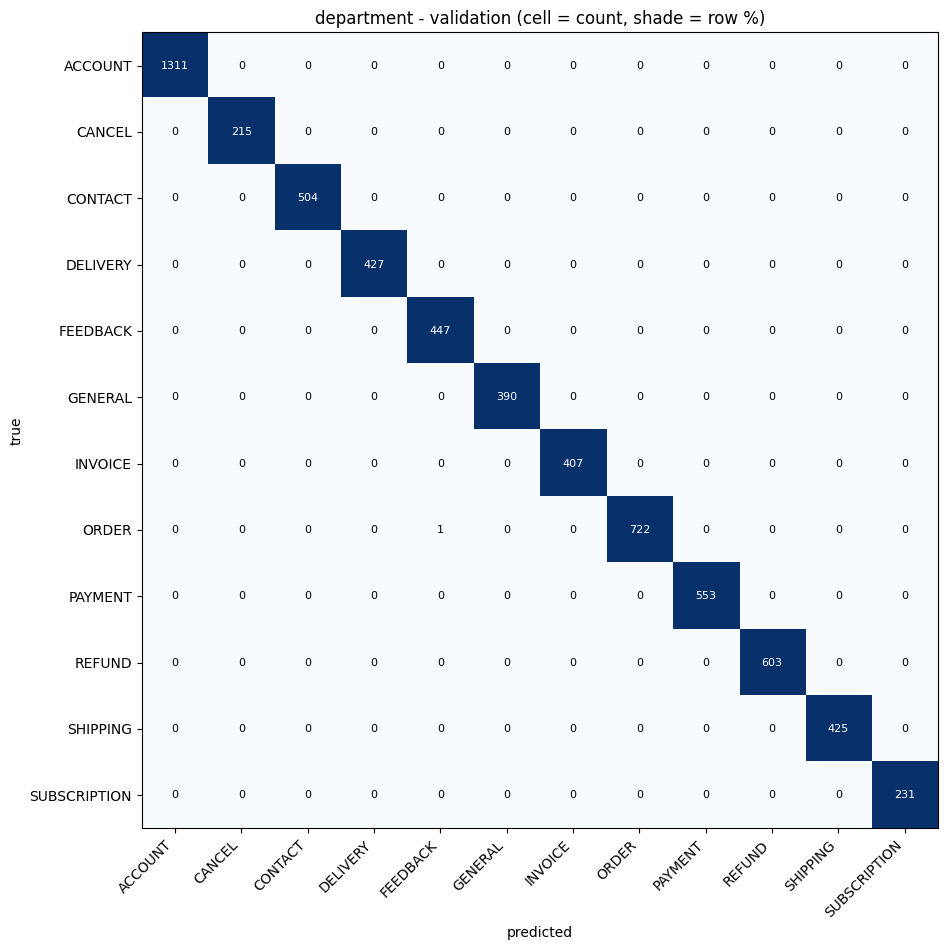


=== SENTIMENT  acc=0.985  balanced_acc=0.976  macro_F1=0.979  weighted_F1=0.985  ECE=0.010
            precision  recall     f1  support
casual          1.000   1.000  1.000    390.0
frustrated      0.957   0.935  0.945    872.0
neutral         0.989   0.993  0.991   4974.0


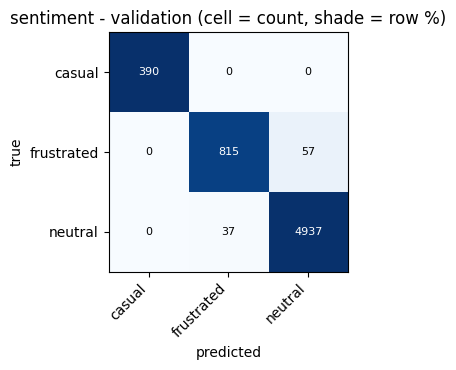


=== URGENCY  acc=1.000  balanced_acc=0.999  macro_F1=0.998  weighted_F1=1.000  ECE=0.001
          precision  recall     f1  support
critical      1.000   0.998  0.999    523.0
greeting      0.990   1.000  0.995    104.0
nonsense      0.997   0.997  0.997    286.0
routine       1.000   1.000  1.000   5323.0


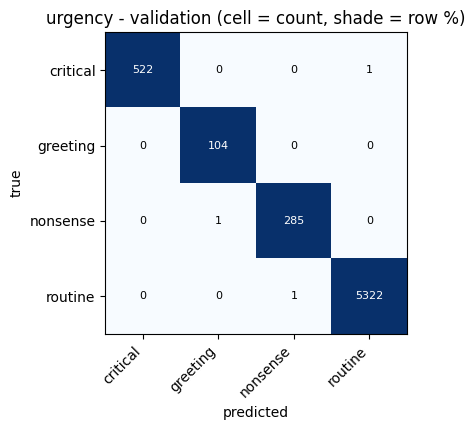

In [ ]:
import time
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report,
                             roc_auc_score, average_precision_score, roc_curve, precision_recall_curve)

SAVE_DIR = "router_artifacts"
shutil.rmtree(SAVE_DIR, ignore_errors=True)
FIG_DIR = f"{SAVE_DIR}/figures"
os.makedirs(FIG_DIR, exist_ok=True)
METRICS = {}


def _py(o):
    if isinstance(o, dict):  return {str(k): _py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_py(v) for v in o]
    if isinstance(o, np.ndarray): return _py(o.tolist())
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o


@torch.no_grad()
def predict_probs_batch(texts, batch_size=128):
    model.eval()
    texts = list(texts)
    parts = {"department": [], "sentiment": [], "urgency": []}
    for i in tqdm(range(0, len(texts), batch_size), desc="predicting", leave=False):
        enc = tokenizer(texts[i:i + batch_size], truncation=True, padding="max_length", max_length=MAX_LEN,
                        return_tensors="pt").to(device)
        outs = model(enc["input_ids"], enc["attention_mask"])
        for name, logits in zip(parts, outs):
            parts[name].append(torch.softmax(logits, dim=1).cpu().numpy())
    return {k: np.concatenate(v) for k, v in parts.items()}


def expected_calibration_error(probs, y_true, n_bins=10):
    conf, correct = probs.max(1), (probs.argmax(1) == y_true).astype(float)
    edges, ece = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)


def plot_cm(cm, labels, title, fname):
    cm = np.asarray(cm)
    norm_cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    n = len(labels)
    fig, ax = plt.subplots(figsize=(max(4.5, 0.75 * n + 2.5), max(3.8, 0.65 * n + 1.8)))
    ax.imshow(norm_cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=45, ha="right"); ax.set_yticklabels(labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if norm_cm[i, j] > 0.5 else "black")
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{fname}", dpi=130)
    plt.show(); plt.close(fig)


val_probs = predict_probs_batch(val_df["instruction"].tolist())
HEAD_INFO = {"department": (department_encoder, "department_id"),
             "sentiment": (sentiment_encoder, "sentiment_id"),
             "urgency": (urgency_encoder, "urgency_id")}

for head, (enc_, col) in HEAD_INFO.items():
    y, P = val_df[col].values, val_probs[head]
    yhat, names = P.argmax(1), [str(c) for c in enc_.classes_]
    ids = np.arange(len(names))
    rep = classification_report(y, yhat, labels=ids, target_names=names, output_dict=True, zero_division=0)
    cm = confusion_matrix(y, yhat, labels=ids)
    METRICS[head] = {
        "n": int(len(y)), "accuracy": accuracy_score(y, yhat), "balanced_accuracy": balanced_accuracy_score(y, yhat),
        "macro_f1": f1_score(y, yhat, average="macro", zero_division=0),
        "weighted_f1": f1_score(y, yhat, average="weighted", zero_division=0),
        "ece": expected_calibration_error(P, y), "classes": names, "confusion_matrix": cm,
        "per_class": {n: {"precision": rep[n]["precision"], "recall": rep[n]["recall"],
                          "f1": rep[n]["f1-score"], "support": rep[n]["support"]} for n in names},
    }
    m = METRICS[head]
    print(f"\n=== {head.upper()}  acc={m['accuracy']:.3f}  balanced_acc={m['balanced_accuracy']:.3f}  "
          f"macro_F1={m['macro_f1']:.3f}  weighted_F1={m['weighted_f1']:.3f}  ECE={m['ece']:.3f}")
    print(pd.DataFrame(m["per_class"]).T.round(3).to_string())
    plot_cm(cm, names, f"{head} - validation (cell = count, shade = row %)", f"cm_{head}.png")


=== critical_detection: 523 positives / 6236   ROC-AUC=1.0000   PR-AUC=1.0000
      precision  recall     f1  flagged  missed
0.25        1.0   1.000  1.000    523.0     0.0
0.50        1.0   0.998  0.999    522.0     1.0

=== frustration_detection: 872 positives / 6236   ROC-AUC=0.9955   PR-AUC=0.9837
      precision  recall     f1  flagged  missed
0.60      0.958   0.933  0.945    850.0    58.0


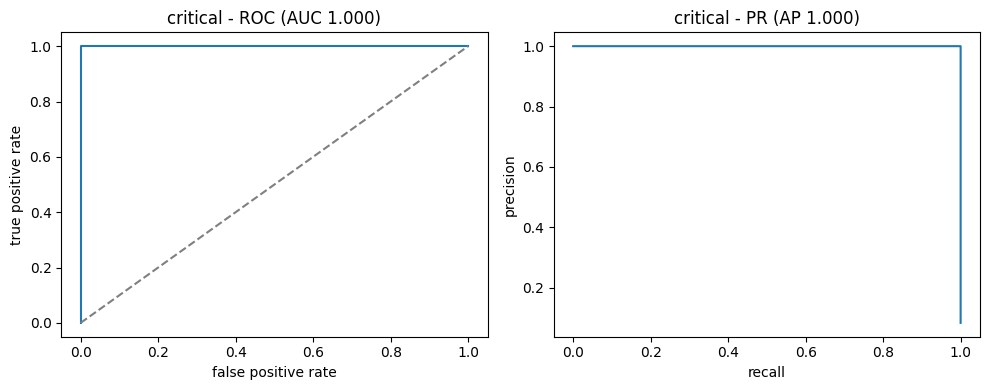

In [ ]:
def binary_report(y_true, score, thresholds):
    y_true = np.asarray(y_true).astype(bool)
    out = {"n": int(len(y_true)), "positives": int(y_true.sum()), "at_threshold": {}}
    if 0 < y_true.sum() < len(y_true):
        out["roc_auc"] = float(roc_auc_score(y_true, score))
        out["pr_auc"] = float(average_precision_score(y_true, score))
    for t in thresholds:
        pred = score >= t
        tp, fp, fn = int((pred & y_true).sum()), int((pred & ~y_true).sum()), int((~pred & y_true).sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        out["at_threshold"][f"{t:.2f}"] = {"precision": prec, "recall": rec,
                                           "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
                                           "flagged": int(pred.sum()), "missed": fn}
    return out


urg_idx = {str(c): i for i, c in enumerate(urgency_encoder.classes_)}
sen_idx = {str(c): i for i, c in enumerate(sentiment_encoder.classes_)}
y_crit = (val_df["urgency_label"] == "critical").values
y_frus = (val_df["sentiment_label"] == "frustrated").values
s_crit = val_probs["urgency"][:, urg_idx["critical"]]
s_frus = val_probs["sentiment"][:, sen_idx["frustrated"]]

METRICS["critical_detection"] = binary_report(y_crit, s_crit, [CFG["review_crit_prob"], CFG["escalate_crit_prob"]])
METRICS["frustration_detection"] = binary_report(y_frus, s_frus, [CFG["frustrated_prob"]])

for name in ["critical_detection", "frustration_detection"]:
    b = METRICS[name]
    print(f"\n=== {name}: {b['positives']} positives / {b['n']}   ROC-AUC={b.get('roc_auc', float('nan')):.4f}   PR-AUC={b.get('pr_auc', float('nan')):.4f}")
    print(pd.DataFrame(b["at_threshold"]).T.round(3).to_string())

if 0 < y_crit.sum() < len(y_crit):
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))
    fpr_, tpr_, _ = roc_curve(y_crit, s_crit)
    axs[0].plot(fpr_, tpr_); axs[0].plot([0, 1], [0, 1], "--", c="grey")
    axs[0].set_title(f"critical - ROC (AUC {METRICS['critical_detection']['roc_auc']:.3f})")
    axs[0].set_xlabel("false positive rate"); axs[0].set_ylabel("true positive rate")
    pr_, rc_, _ = precision_recall_curve(y_crit, s_crit)
    axs[1].plot(rc_, pr_); axs[1].set_title(f"critical - PR (AP {METRICS['critical_detection']['pr_auc']:.3f})")
    axs[1].set_xlabel("recall"); axs[1].set_ylabel("precision")
    fig.tight_layout(); fig.savefig(f"{FIG_DIR}/roc_pr_critical.png", dpi=130); plt.show(); plt.close(fig)

VALIDATION SAMPLE (3000 msgs)  tier accuracy=0.985  macro_F1=0.980  emergency_catch_rate=1.000  missed_emergencies=0  false_escalations=0
   precision  recall     f1  support
1      1.000   1.000  1.000    234.0
2      0.941   0.938  0.939    339.0
3      0.991   0.990  0.990   2234.0
4      0.985   1.000  0.992    193.0


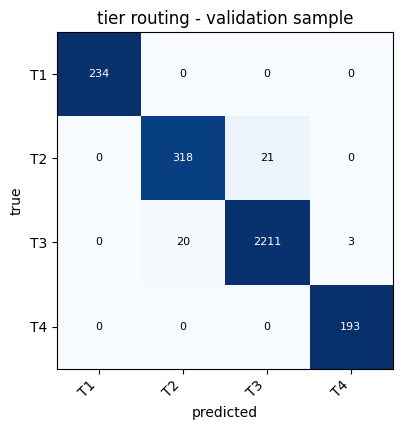


accuracy by data source:
                                  mean  count
source                                       
bitext                           0.981   2309
synthetic_critical_angry         1.000     66
synthetic_critical_polite        1.000     79
synthetic_frustrated_routine     1.000    144
synthetic_greeting               1.000     51
synthetic_greeting_plus_request  1.000    143
synthetic_nonsense               1.000    142
synthetic_urgent_but_routine     0.985     66

GOLD SET (34 msgs)  tier accuracy=1.000  macro_F1=1.000  emergency_catch_rate=1.000  missed_emergencies=0  false_escalations=0
   precision  recall   f1  support
1        1.0     1.0  1.0      7.0
2        1.0     1.0  1.0      5.0
3        1.0     1.0  1.0     11.0
4        1.0     1.0  1.0     11.0

gold accuracy by kind:
            mean  count
kind                   
critical     1.0      7
faq          1.0     11
frustrated   1.0      5
gibberish    1.0      3
greeting     1.0      4
offtopic     1.0   

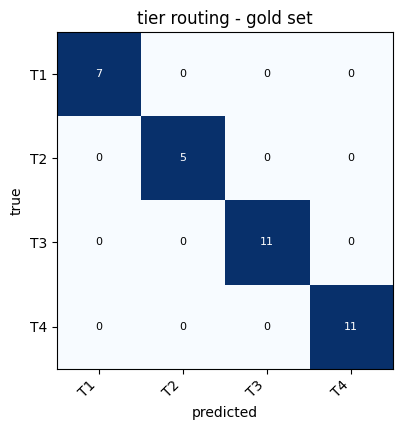

In [ ]:
TIER_LABELS = [1, 2, 3, 4]


def tier_metrics(expected, got):
    expected, got = np.asarray(expected), np.asarray(got)
    rep = classification_report(expected, got, labels=TIER_LABELS, output_dict=True, zero_division=0)
    emerg = expected == 1
    return {
        "n": int(len(expected)), "accuracy": float((expected == got).mean()),
        "macro_f1": float(f1_score(expected, got, labels=TIER_LABELS, average="macro", zero_division=0)),
        "per_tier": {str(t): {"precision": rep[str(t)]["precision"], "recall": rep[str(t)]["recall"],
                              "f1": rep[str(t)]["f1-score"], "support": rep[str(t)]["support"]} for t in TIER_LABELS},
        "confusion_matrix": confusion_matrix(expected, got, labels=TIER_LABELS),
        "emergency_catch_rate": float((got[emerg] <= 2).mean()) if emerg.any() else float("nan"),
        "missed_emergencies": int((got[emerg] >= 3).sum()),
        "false_escalations": int(((expected > 1) & (got == 1)).sum()),
    }


def expected_tier(urg, sen):
    if urg == "critical": return 1
    if urg in ("greeting", "nonsense"): return 4
    return 2 if sen == "frustrated" else 3


def pred_from_probs(text, i, probs):
    d = probs["department"][i]; top = int(d.argmax())
    return {"text": text, "department": str(department_encoder.classes_[top]), "department_confidence": float(d[top]),
            "urgency_probs": {str(c): float(p) for c, p in zip(urgency_encoder.classes_, probs["urgency"][i])},
            "sentiment_probs": {str(c): float(p) for c, p in zip(sentiment_encoder.classes_, probs["sentiment"][i])}}


EVAL_N = 3000
ev = val_df.sample(min(EVAL_N, len(val_df)), random_state=SEED).reset_index(drop=True)
ev["expected"] = [expected_tier(u, s) for u, s in zip(ev["urgency_label"], ev["sentiment_label"])]
ev_texts = ev["instruction"].tolist()
ev_probs = predict_probs_batch(ev_texts)
ev_emb = embed_texts(ev_texts)
emb_by_text = {t: ev_emb[i] for i, t in enumerate(ev_texts)}


def _retrieve_cached(text, dept, dept_conf):
    i, sim = best_match(emb_by_text[text], pool_embs, pool_cats, dept, dept_conf, CFG)
    return {"reply": pool_df.iloc[i]["response"], "similarity": sim, "matched_instruction": pool_df.iloc[i]["instruction"]}


ev["got"] = [route_ticket(pred_from_probs(t, i, ev_probs), retrieve_fn=_retrieve_cached, cfg=CFG)["tier"]
             for i, t in enumerate(ev_texts)]
METRICS["end_to_end_val"] = tier_metrics(ev["expected"], ev["got"])
m = METRICS["end_to_end_val"]
print(f"VALIDATION SAMPLE ({m['n']} msgs)  tier accuracy={m['accuracy']:.3f}  macro_F1={m['macro_f1']:.3f}  "
      f"emergency_catch_rate={m['emergency_catch_rate']:.3f}  missed_emergencies={m['missed_emergencies']}  false_escalations={m['false_escalations']}")
print(pd.DataFrame(m["per_tier"]).T.round(3).to_string())
plot_cm(m["confusion_matrix"], [f"T{t}" for t in TIER_LABELS], "tier routing - validation sample", "cm_tiers_val.png")
print("\naccuracy by data source:")
print(ev.assign(ok=ev["expected"] == ev["got"]).groupby("source")["ok"].agg(["mean", "count"]).round(3).to_string())


METRICS["gold"] = tier_metrics(res["expected"], res["got"])
g = METRICS["gold"]
print(f"\nGOLD SET ({g['n']} msgs)  tier accuracy={g['accuracy']:.3f}  macro_F1={g['macro_f1']:.3f}  "
      f"emergency_catch_rate={g['emergency_catch_rate']:.3f}  missed_emergencies={g['missed_emergencies']}  false_escalations={g['false_escalations']}")
print(pd.DataFrame(g["per_tier"]).T.round(3).to_string())
print("\ngold accuracy by kind:")
print(res.assign(ok=res["expected"] == res["got"]).groupby("kind")["ok"].agg(["mean", "count"]).round(3).to_string())
plot_cm(g["confusion_matrix"], [f"T{t}" for t in TIER_LABELS], "tier routing - gold set", "cm_tiers_gold.png")

In [ ]:
intent_by_norm = dict(zip(df["instruction"].map(norm), df["intent"]))
bit_idx = ev.index[ev["source"] == "bitext"]
hits_intent, hits_dept, sims = [], [], []
for i in bit_idx:
    d = ev_probs["department"][i]; top = int(d.argmax())
    j, sim = best_match(ev_emb[i], pool_embs, pool_cats, str(department_encoder.classes_[top]), float(d[top]), CFG)
    true_intent = intent_by_norm.get(norm(ev_texts[i]))
    hits_intent.append(pool_df.iloc[j]["intent"] == true_intent)
    hits_dept.append(pool_df.iloc[j]["category"] == ev.loc[i, "category"])
    sims.append(sim)

METRICS["retrieval"] = {
    "n": int(len(bit_idx)),
    "top1_intent_accuracy": float(np.mean(hits_intent)) if hits_intent else float("nan"),
    "top1_department_accuracy": float(np.mean(hits_dept)) if hits_dept else float("nan"),
    "median_similarity": float(np.median(sims)) if sims else float("nan"),
    "threshold": float(CFG["retrieval_min_sim"]),
    "answer_rate_in_domain": float(np.mean(np.array(sims) >= CFG["retrieval_min_sim"])) if sims else float("nan"),
}
METRICS["retrieval"]["leak_rate_off_topic"] = float(np.mean(neg_sims >= CFG["retrieval_min_sim"]))
r_ = METRICS["retrieval"]
print(f"RETRIEVAL on {r_['n']} unseen Bitext questions: top-1 intent acc={r_['top1_intent_accuracy']:.3f} | "
      f"top-1 department acc={r_['top1_department_accuracy']:.3f} | answer rate={r_['answer_rate_in_domain']:.3f} | "
      f"off-topic leak rate={r_.get('leak_rate_off_topic', float('nan')):.3f}")

lat = []
for t in [x[0] for x in GOLD][:20]:
    t0 = time.perf_counter(); support_bot(t); lat.append((time.perf_counter() - t0) * 1000)
METRICS["latency_ms"] = {"median": float(np.median(lat)), "p95": float(np.percentile(lat, 95)), "device": str(device)}
print(f"latency per message on {device}: median={np.median(lat):.0f} ms, p95={np.percentile(lat, 95):.0f} ms")

RETRIEVAL on 2309 unseen Bitext questions: top-1 intent acc=0.994 | top-1 department acc=1.000 | answer rate=0.998 | off-topic leak rate=0.000
latency per message on cuda: median=16 ms, p95=21 ms


Department accuracy (val)      1.000
Urgency macro-F1 (val)         0.998
Sentiment macro-F1 (val)       0.979
Critical ROC-AUC (val)         1.000
Tier accuracy (val sample)     0.985
Tier accuracy (gold)           1.000
Emergency catch rate (gold)    1.000
Retrieval top-1 intent acc     0.994


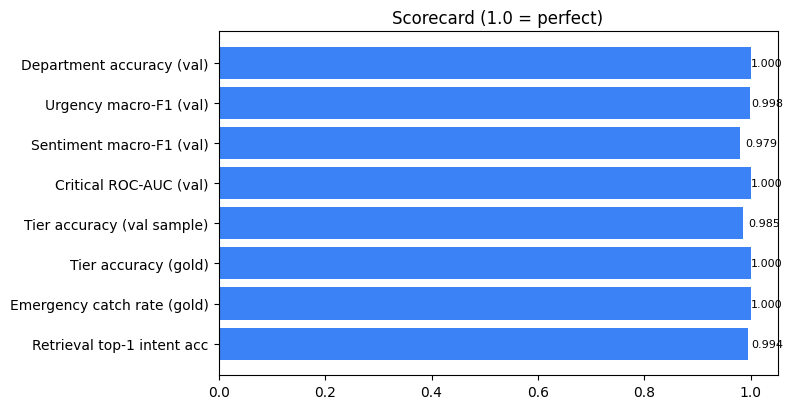

saved: router_artifacts/metrics.json | figures: ['cm_department.png', 'cm_sentiment.png', 'cm_tiers_gold.png', 'cm_tiers_val.png', 'cm_urgency.png', 'roc_pr_critical.png', 'scorecard.png']


In [ ]:
METRICS["headline"] = {
    "Department accuracy (val)": METRICS["department"]["accuracy"],
    "Urgency macro-F1 (val)": METRICS["urgency"]["macro_f1"],
    "Sentiment macro-F1 (val)": METRICS["sentiment"]["macro_f1"],
    "Critical ROC-AUC (val)": METRICS["critical_detection"].get("roc_auc", float("nan")),
    "Tier accuracy (val sample)": METRICS["end_to_end_val"]["accuracy"],
    "Tier accuracy (gold)": METRICS["gold"]["accuracy"],
    "Emergency catch rate (gold)": METRICS["gold"]["emergency_catch_rate"],
    "Retrieval top-1 intent acc": METRICS["retrieval"]["top1_intent_accuracy"],
}
METRICS["run_info"] = {"epochs": EPOCHS, "lr": LR, "n_train": int(len(train_df)), "n_val": int(len(val_df)),
                       "gold_size": int(len(GOLD)), "routing_config": CFG}

scorecard = pd.Series(METRICS["headline"]).round(3)
print(scorecard.to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
vals = scorecard.fillna(0)
ax.barh(vals.index[::-1], vals.values[::-1], color="#3b82f6")
ax.set_xlim(0, 1.05); ax.set_title("Scorecard (1.0 = perfect)")
for y_, v_ in enumerate(vals.values[::-1]):
    ax.text(min(v_ + 0.01, 1.0), y_, f"{v_:.3f}", va="center", fontsize=8)
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/scorecard.png", dpi=130); plt.show(); plt.close(fig)

with open(f"{SAVE_DIR}/metrics.json", "w") as f:
    json.dump(_py(METRICS), f, indent=2)
scorecard.to_csv(f"{SAVE_DIR}/metrics_summary.csv", header=["value"])
print("saved:", f"{SAVE_DIR}/metrics.json", "| figures:", sorted(os.listdir(FIG_DIR)))

## 16. Save deployable artifacts

Everything an application needs is written to `router_artifacts/`: classifier weights and config, tokenizer, labels, `routing.py`, calibrated thresholds, a local copy of the MiniLM encoder (so it runs offline), pool embeddings, `replies.csv` with a cleaned reply column, the gold results, and the metrics from section 15.

In [ ]:
os.makedirs(SAVE_DIR, exist_ok=True)


torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, f"{SAVE_DIR}/router_weights.pt")
model.distilbert.config.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

with open(f"{SAVE_DIR}/labels.json", "w") as f:
    json.dump({"departments": department_encoder.classes_.tolist(), "urgencies": urgency_encoder.classes_.tolist(),
               "sentiments": sentiment_encoder.classes_.tolist(), "max_len": int(MAX_LEN),
               "classifier_base": "distilbert-base-uncased", "retrieval_model": EMB_MODEL}, f, indent=2)


with open(f"{SAVE_DIR}/routing_config.json", "w") as f:
    json.dump(CFG, f, indent=2, default=float)
with open(f"{SAVE_DIR}/routing.py", "w") as f:
    f.write(ROUTING_SRC)


emb_model.save_pretrained(f"{SAVE_DIR}/retrieval_model")
emb_tok.save_pretrained(f"{SAVE_DIR}/retrieval_model")
np.save(f"{SAVE_DIR}/pool_embeddings.npy", pool_embs)

out_replies = pool_df[["instruction", "category", "intent", "response"]].copy()
out_replies["response"] = out_replies["response"].fillna("").astype(str)
out_replies["response_clean"] = out_replies["response"].map(clean_response)

stray = out_replies["response_clean"].str.contains(r"\{\{|\}\}", regex=True)
if stray.any():
    print(f"note: {int(stray.sum())} replies still had braces - stripping them")
    out_replies.loc[stray, "response_clean"] = out_replies.loc[stray, "response_clean"].str.replace(r"\{\{|\}\}", "", regex=True)
out_replies.to_csv(f"{SAVE_DIR}/replies.csv", index=False)


res.to_csv(f"{SAVE_DIR}/gold_results.csv", index=False)

for root, _, files in os.walk(SAVE_DIR):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f"{os.path.getsize(p) / 1e6:9.2f} MB  {p}")

In [ ]:
ZIP_BASE = "router_artifacts"
zip_path = shutil.make_archive(ZIP_BASE, "zip", SAVE_DIR)
print(f"created {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
with open(f"{SAVE_DIR}/labels.json") as f:
    print("labels.json keys:", list(json.load(f)))